# BCNN results — figures

Figures for the model selected by hyperparameter tuning (`tune_bcnn.py`),

The notebook reads the best model file 

Figures:

1. **Metrics table**: accuracy, precision, recall, F1 (macro and weighted) and cross-entropy for each level.
2. **Overall accuracy per level**: bar plot with 95% confidence intervals.
3. **F1 per class**: one panel per level.
4. **Confusion matrices**: one per level, normalised by true class (row).
5. **Correct to which level?**: for each terminal node, the share of test images correct at all levels, correct only to level 2, correct only at level 1, or incorrect at all levels.

All metrics use the test set. Test images with no label at a level (`-1`, e.g. Copepoda at level 3) are left out of that level's metrics.
Levels are numbered from the coarsest: **Level 1** (2 classes), **Level 2** (7 classes) and **Level 3** (16 classes). `get_bcnn_results.ipynb` calls these levels 0, 1 and 2.

In [1]:
import os
import glob
import json

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             log_loss, confusion_matrix)

## Configuration

In [2]:
run_name = 'BCNN_ZOOP_20261125_092735_densenet121_3_tuned.pth'

# Models_results lives at the repository root; find it whether the notebook runs from the root or Zooplankton-MNR/
results_directory = next(
    p for p in [os.path.abspath('Models_results'), os.path.abspath(os.path.join('..', 'Models_results'))]
    if os.path.isdir(p)
)
tuning_directory = os.path.join(results_directory, 'tuning')

print(f'Run: {run_name}')
predictions_path = os.path.join(results_directory, 'predictions', run_name)
metadata_path = os.path.join(results_directory, 'environment', run_name)

SAVE_FIG = True
FIG_DIR = os.path.join('figures', run_name.removesuffix('.pth'))

# Colours (same as dataset_overview.ipynb)
CATEGORICAL = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
NEUTRAL = '#8a8984'
INK, INK_2, GRID = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({'font.size': 9, 'axes.edgecolor': INK_2, 'axes.labelcolor': INK_2,
                     'xtick.color': INK_2, 'ytick.color': INK_2})

def clean_axes(ax, grid_axis='y'):
    ax.grid(axis=grid_axis, color=GRID, lw=0.8, zorder=0)
    ax.set_axisbelow(True)
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)

def save(fig, name):
    if SAVE_FIG:
        os.makedirs(FIG_DIR, exist_ok=True)
        fig.savefig(os.path.join(FIG_DIR, name + '.png'), dpi=200, bbox_inches='tight')
        fig.savefig(os.path.join(FIG_DIR, name + '.pdf'), bbox_inches='tight')

Run: BCNN_ZOOP_20261125_092735_densenet121_3_tuned.pth


## Load predictions and metadata

In [3]:
metadata = torch.load(metadata_path, weights_only = False, map_location = 'cpu')
predictions = torch.load(predictions_path, map_location = 'cpu')

levels = metadata['levels']
classes = metadata['classes']                 # list per level, coarsest first
level_names = [f'Level {l + 1}' for l in range(levels)]
print(f"Run: {metadata['run_name']} | model: {metadata['model_name']} | levels: {levels}")
print('Hyperparameters:', metadata['hyperparameters'])

if 'split' in metadata:
    print('Split (train / val / test):', metadata['split'])
if metadata.get('model_kind') == 'production':
    print('NOTE: production model - its small test set overlaps the evaluation training data; '
          'report the evaluation model metrics instead.')

# predictions = (labels, probs, preds, logits); each is a list over levels
y_true, y_pred, y_prob, n_missing = [], [], [], []
for l in range(levels):
    labels = predictions[0][l].numpy()
    keep = labels != -1                       # drop test images with no label at this level
    y_true.append(labels[keep])
    y_pred.append(predictions[2][l].numpy()[keep])
    y_prob.append(predictions[1][l].numpy()[keep])
    n_missing.append(int((~keep).sum()))

for l in range(levels):
    print(f'{level_names[l]}: {len(y_true[l]):,} labelled test images ({n_missing[l]:,} without a label left out)')

Run: BCNN_ZOOP_20261125_092735_densenet121_3_tuned | model: densenet121 | levels: 3
Hyperparameters: {'loss_fn': {'criterion': 'CrossEntropyLoss', 'alpha': [0.3333333333333333, 0.3333333333333333, 0.3333333333333333], 'thresholds': None}, 'optimizer': 'Adam', 'lr': 0.0005, 'epochs': 50, 'scheduler': {'type': 'CosineAnnealingLR', 'T_max': 50}, 'early_stopping': {'patience': 15, 'delta': 0.0005}, 'batch_size': 64}
Split (train / val / test): {'train': 0.7, 'val': 0.1, 'test': 0.2}
Level 1: 19,714 labelled test images (0 without a label left out)
Level 2: 16,773 labelled test images (2,941 without a label left out)
Level 3: 15,735 labelled test images (3,979 without a label left out)


## 1. Metrics table

In [4]:
rows = []
for l in range(levels):
    t, p, pr = y_true[l], y_pred[l], y_prob[l]
    rows.append({
        'Level': level_names[l],
        'Classes': len(classes[l]),
        'Test images': len(t),
        'Accuracy': accuracy_score(t, p),
        'Precision (macro)': precision_score(t, p, average='macro', zero_division=0),
        'Precision (weighted)': precision_score(t, p, average='weighted', zero_division=0),
        'Recall (macro)': recall_score(t, p, average='macro', zero_division=0),
        'Recall (weighted)': recall_score(t, p, average='weighted', zero_division=0),
        'F1 (macro)': f1_score(t, p, average='macro', zero_division=0),
        'F1 (weighted)': f1_score(t, p, average='weighted', zero_division=0),
        'Cross-entropy': log_loss(t, pr, labels=list(range(len(classes[l])))),
    })
metrics_df = pd.DataFrame(rows).set_index('Level')

if SAVE_FIG:
    os.makedirs(FIG_DIR, exist_ok=True)
    metrics_df.to_csv(os.path.join(FIG_DIR, 'metrics_per_level.csv'))

metrics_df.style.format({c: '{:.4f}' for c in metrics_df.columns if c not in ('Classes', 'Test images')}
                        | {'Test images': '{:,}'})

,Classes,Test images,Accuracy,Precision (macro),Precision (weighted),Recall (macro),Recall (weighted),F1 (macro),F1 (weighted),Cross-entropy
Level,,,,,,,,,,
Level 1,2,"19,714",0.9895,0.9896,0.9895,0.9878,0.9895,0.9887,0.9895,0.0329
Level 2,7,"16,773",0.9887,0.9833,0.9887,0.9808,0.9887,0.9821,0.9887,0.0373
Level 3,16,"15,735",0.9715,0.9746,0.9715,0.9688,0.9715,0.9714,0.9714,0.0968


## 2. Overall accuracy per level

Error bars are 95% Wilson confidence intervals for each accuracy, given the number of labelled test images at that level.

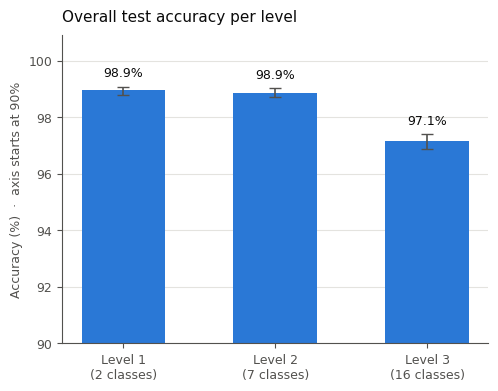

In [12]:
def wilson_ci(k, n, z=1.96):
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half

acc = metrics_df['Accuracy'].values
n = metrics_df['Test images'].values
ci = np.array([wilson_ci(a * m, m) for a, m in zip(acc, n)])
yerr = np.vstack([acc - ci[:, 0], ci[:, 1] - acc]) * 100

fig, ax = plt.subplots(figsize=(5.5, 4))
x = np.arange(levels)
ax.bar(x, acc * 100, width=0.55, color=CATEGORICAL[0], zorder=2)
ax.errorbar(x, acc * 100, yerr=yerr, fmt='none', ecolor=INK_2, elinewidth=1.2, capsize=4, zorder=3)
for xi, a, hi in zip(x, acc, ci[:, 1]):
    ax.text(xi, hi * 100 + 0.25, f'{a:.1%}', ha='center', va='bottom', fontsize=9, color=INK)

ax.set_xticks(x, [f'{level_names[l]}\n({len(classes[l])} classes)' for l in range(levels)])
lo = np.floor(min(ci[:, 0]) * 100 / 5) * 5 - 5   # start the axis just below the lowest CI, rounded to 5
ax.set_ylim(max(lo, 0), 100.9)
ax.set_ylabel(f'Accuracy (%)  ·  axis starts at {max(lo, 0):.0f}%')
ax.set_title('Overall test accuracy per level', loc='left', fontsize=11, color=INK, pad=10)
clean_axes(ax)
save(fig, 'accuracy_per_level')
plt.show()

## 3. F1 per class

Bars are coloured by the class's level-2 group, using the same colours as `dataset_overview.ipynb`.

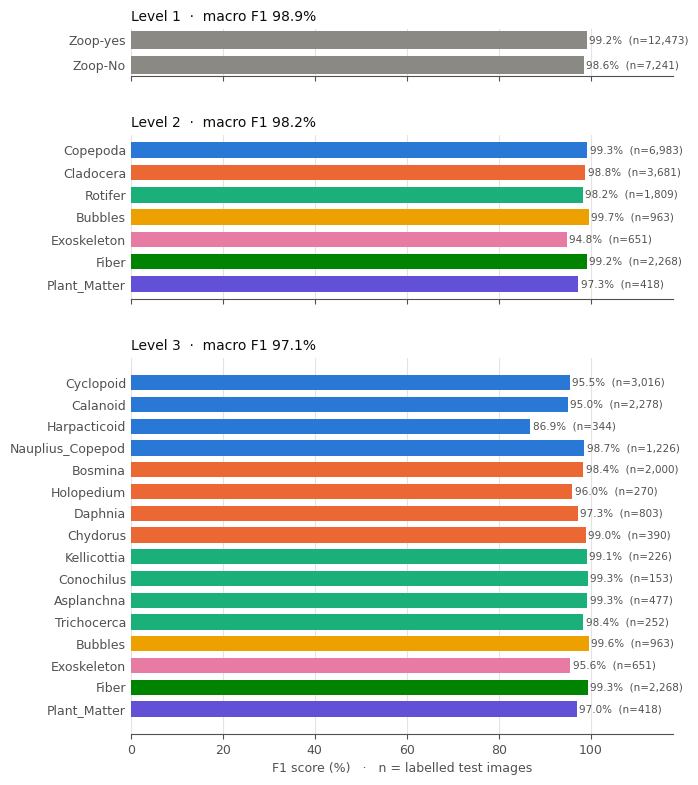

In [13]:
# Map every level-3 (and level-2) class to its level-2 group via the saved dataset
hier_dataset = metadata['dataset']
l2_of = {}
for l in range(1, levels):
    for lab_fine, lab_l2 in zip(hier_dataset.labels[l], hier_dataset.labels[1]):
        if lab_fine is not None and lab_l2 is not None:
            l2_of.setdefault((l, classes[l][lab_fine]), classes[1][lab_l2])
L2_COLOR = {name: CATEGORICAL[i % len(CATEGORICAL)] for i, name in enumerate(classes[1])}

def bar_colors(l):
    if l == 0:
        return [NEUTRAL] * len(classes[0])
    return [L2_COLOR.get(l2_of.get((l, c)), NEUTRAL) for c in classes[l]]

per_class_f1 = [f1_score(y_true[l], y_pred[l], labels=list(range(len(classes[l]))), average=None, zero_division=0)
                for l in range(levels)]
support = [np.bincount(y_true[l], minlength=len(classes[l])) for l in range(levels)]

heights = [len(classes[l]) for l in range(levels)]
fig, axes = plt.subplots(levels, 1, figsize=(7, 0.27 * sum(heights) + 0.8 * levels),
                         gridspec_kw={'height_ratios': heights, 'hspace': 0.3}, sharex=True)
for l, ax in enumerate(np.atleast_1d(axes)):
    yy = np.arange(len(classes[l]))
    ax.barh(yy, per_class_f1[l] * 100, height=0.7, color=bar_colors(l), zorder=2)
    for yi, v, s in zip(yy, per_class_f1[l], support[l]):
        ax.text(v * 100 + 0.5, yi, f'{v:.1%}  (n={s:,})', va='center', fontsize=7.5, color=INK_2)
    ax.set_yticks(yy, classes[l])
    ax.invert_yaxis()
    ax.set_xlim(0, 118)
    ax.set_title(f'{level_names[l]}  ·  macro F1 {metrics_df.loc[level_names[l], "F1 (macro)"]:.1%}',
                 loc='left', fontsize=10, color=INK)
    ax.tick_params(axis='y', length=0)
    clean_axes(ax, grid_axis='x')
    ax.spines['left'].set_visible(False)
ax.set_xticks(range(0, 101, 20))
ax.set_xlabel('F1 score (%)   ·   n = labelled test images')
save(fig, 'f1_per_class')
plt.show()

## 4. Confusion matrices (row-normalised)

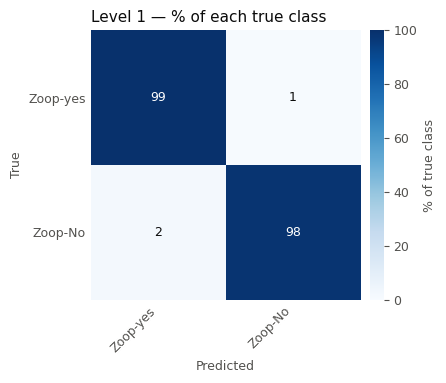

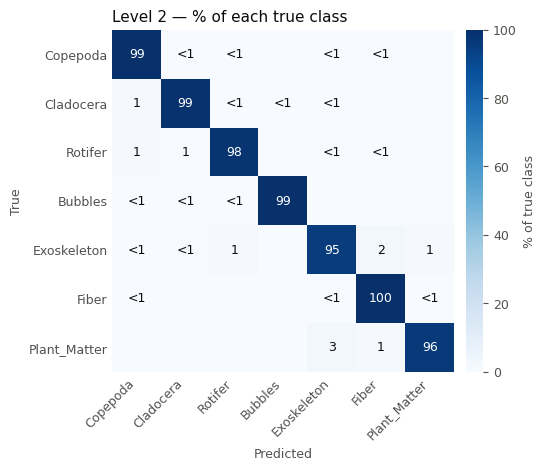

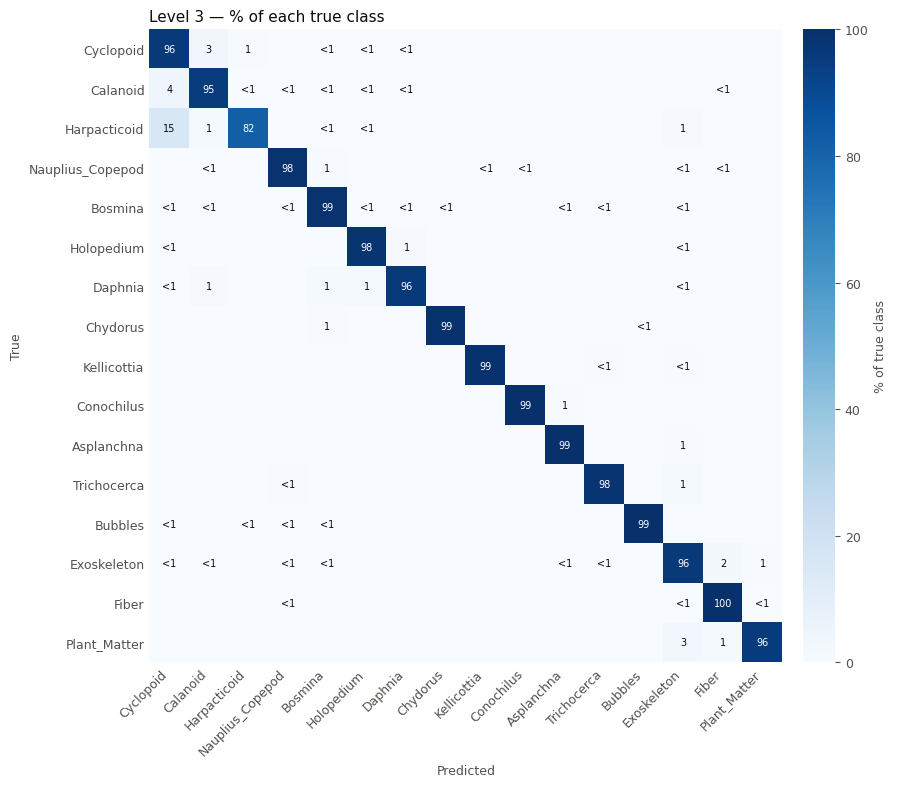

In [14]:
for l in range(levels):
    k = len(classes[l])
    cm = confusion_matrix(y_true[l], y_pred[l], labels=list(range(k)))
    cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)

    size = max(3.5, 0.42 * k + 1.5)
    fig, ax = plt.subplots(figsize=(size + 0.8, size))
    im = ax.imshow(cm_norm * 100, cmap='Blues', vmin=0, vmax=100)
    for i in range(k):
        for j in range(k):
            v = cm_norm[i, j]
            if cm[i, j] > 0:
                ax.text(j, i, f'{100 * v:.0f}' if v >= 0.005 else '<1', ha='center', va='center',
                        fontsize=7 if k > 8 else 9, color='white' if v > 0.6 else INK)
    ax.set_xticks(range(k), classes[l], rotation=45, ha='right')
    ax.set_yticks(range(k), classes[l])
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(f'{level_names[l]} — % of each true class', loc='left', fontsize=11, color=INK)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
    cb.set_label('% of true class')
    cb.outline.set_visible(False)
    save(fig, f'confusion_matrix_level{l + 1}')
    plt.show()

## 5. Correct to which level? (per terminal node)

Each test image with a terminal-node (level-3) label is assigned to one group, by how far down the hierarchy its predictions are correct:
- **Correct at all levels**: levels 1, 2 and 3 all correct
- **Correct only to level 2**: levels 1 and 2 correct, level 3 wrong
- **Correct only at level 1**: level 1 correct, levels 2 and 3 wrong
- **Incorrect at all levels**
- **Other**: combinations that don't follow the hierarchy (e.g. level 3 correct but level 1 wrong)

Images without a level-3 label (Copepoda, Cladocera, Rotifer, Debris) are not included. The top panel shows the full 100%; the bottom panel zooms in on the images not correct at all levels.

,Test images,Correct at all levels,Correct only to level 2,Correct only at level 1,Incorrect at all levels,Other
Cyclopoid,3016,95.95,3.75,0.17,0.00,0.13
Calanoid,2278,94.78,4.48,0.22,0.09,0.44
Harpacticoid,344,81.10,17.15,0.58,0.58,0.58
Nauplius_Copepod,1226,96.74,0.49,0.49,0.49,1.79
Bosmina,2000,98.05,0.85,0.55,0.05,0.50
Holopedium,270,97.04,1.11,0.74,0.00,1.11
Daphnia,803,95.27,3.49,0.37,0.12,0.75
Chydorus,390,98.97,0.77,0.26,0.00,0.00
Kellicottia,226,96.90,0.44,0.00,0.44,2.21
Conochilus,153,98.69,0.65,0.00,0.00,0.65


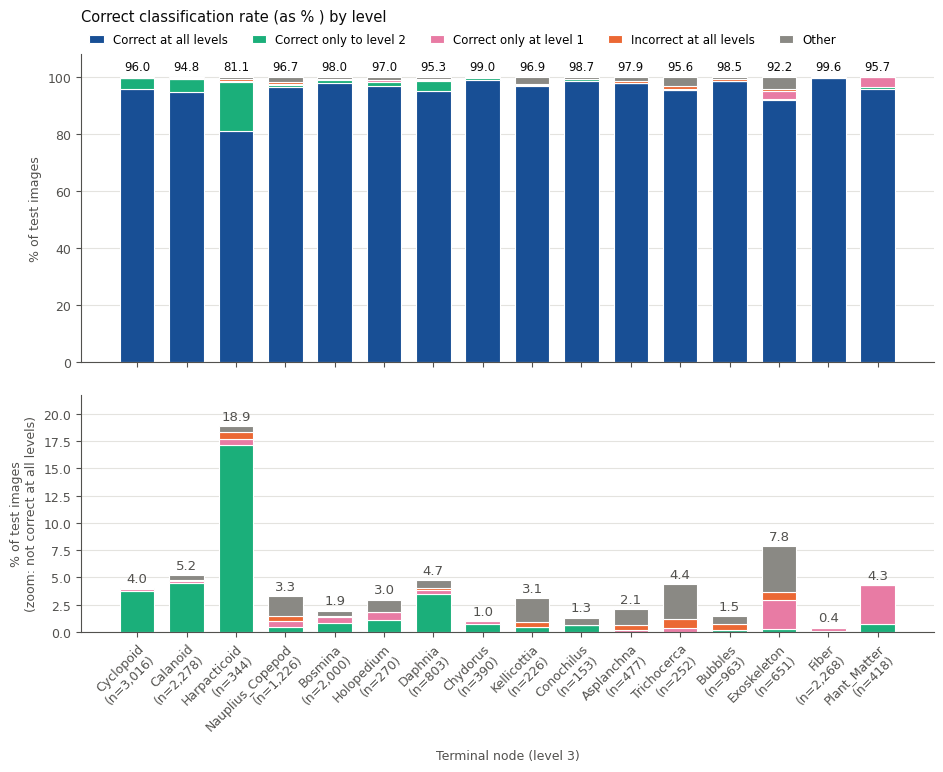

In [18]:
# assert levels == 3, 'This figure assumes 3 levels'

true_all = [predictions[0][l].numpy() for l in range(levels)]
pred_all = [predictions[2][l].numpy() for l in range(levels)]
has_terminal = true_all[2] != -1
correct = np.stack([(pred_all[l] == true_all[l])[has_terminal] for l in range(levels)], axis=1)
terminal = true_all[2][has_terminal]

c1, c2, c3 = correct[:, 0], correct[:, 1], correct[:, 2]
GROUPS = ['Correct at all levels', 'Correct only to level 2', 'Correct only at level 1',
          'Incorrect at all levels', 'Other']
group = np.select(
    [c1 & c2 & c3, c1 & c2 & ~c3, c1 & ~c2 & ~c3, ~c1 & ~c2 & ~c3],
    [0, 1, 2, 3], default=4)

# Ordered from fully correct (dark blue) to fully wrong (orange); 'Other' is neutral grey
GROUP_COLORS = ['#184f95', '#1baf7a', '#e87ba4', '#eb6834', NEUTRAL]

k = len(classes[2])
counts_tg = np.zeros((k, len(GROUPS)), dtype=int)
np.add.at(counts_tg, (terminal, group), 1)
n_per_class = counts_tg.sum(axis=1)
pct = 100 * counts_tg / np.maximum(n_per_class[:, None], 1)

group_df = pd.DataFrame(pct, index=classes[2], columns=GROUPS).round(2)
group_df.insert(0, 'Test images', n_per_class)
if SAVE_FIG:
    os.makedirs(FIG_DIR, exist_ok=True)
    group_df.to_csv(os.path.join(FIG_DIR, 'correct_depth_per_terminal_node.csv'))
display(group_df)

show = [g for g in range(len(GROUPS)) if counts_tg[:, g].sum() > 0]   # drop empty groups (e.g. no 'Other')
x = np.arange(k)
fig, (ax_top, ax_zoom) = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True,
                                      gridspec_kw={'height_ratios': [1.3, 1], 'hspace': 0.12})

# Top: full 100%
bottom = np.zeros(k)
for g in show:
    ax_top.bar(x, pct[:, g], bottom=bottom, width=0.7, color=GROUP_COLORS[g], edgecolor='white',
               lw=0.8, label=GROUPS[g], zorder=2)
    bottom += pct[:, g]
for xi, v in zip(x, pct[:, 0]):
    ax_top.text(xi, 101.5, f'{v:.1f}', ha='center', va='bottom', fontsize=8.5, color=INK)
ax_top.set_ylim(0, 108)
ax_top.set_yticks(range(0, 101, 20))
ax_top.set_ylabel('% of test images')
ax_top.set_title('Correct classification rate (as % ) by level',
                 loc='left', fontsize=10.5, color=INK, pad=24)
clean_axes(ax_top)

# Bottom: zoom on the images that are not correct at all levels
bottom = np.zeros(k)
for g in [g for g in show if g != 0]:
    ax_zoom.bar(x, pct[:, g], bottom=bottom, width=0.7, color=GROUP_COLORS[g], edgecolor='white',
                lw=0.8, zorder=2)
    bottom += pct[:, g]
for xi, v in zip(x, bottom):
    if v > 0:
        ax_zoom.text(xi, v + bottom.max() * 0.015, f'{v:.1f}', ha='center', va='bottom', fontsize=9.5, color=INK_2)
ax_zoom.set_ylim(0, bottom.max() * 1.15)
ax_zoom.set_ylabel('% of test images\n(zoom: not correct at all levels)')
clean_axes(ax_zoom)

ax_zoom.set_xticks(x, [f'{c}\n(n={n:,})' for c, n in zip(classes[2], n_per_class)], rotation=45, ha='right',
                   rotation_mode='anchor', fontsize=9)
ax_zoom.set_xlabel('Terminal node (level 3)')
ax_top.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=len(show), frameon=False, fontsize=8.5,
              handlelength=1.2, borderaxespad=0.3)

save(fig, 'correct_depth_per_terminal_node')
plt.show()